# BBO capstone results after 9 graded weeks

This notebook rebuilds every headline number and figure from `data/` and
`results/`, then works through each regime set in `src/bbo/config.py` for
the week-10 queries. It needs no inputs and runs in under a minute.

1. Results table (recomputed)
2. Progress figure
3. Calibration record
4. The regimes, worked through:
   - trust-region EI (F3, F7)
   - triangulation (F4, F1)
   - posterior mean on a noisy function (F2)
   - bank (F5)
5. Reproducibility check: re-deriving the submitted week-10 queries

In [1]:
import sys, re, warnings, subprocess, importlib.util
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from bbo import data, surrogates, acquisition, triangulation
from bbo.config import CONFIG
DATA = ROOT / "data"
log = pd.read_csv(ROOT / "results" / "query_log.csv")
pd.set_option("display.precision", 10)

## 1. Results table

This table is computed directly from the supplied `.npy` files and
`observations.csv`. *Records* counts the weeks whose result beat everything
before it, including the supplied data.

In [2]:
rows = []
for i, cfg in CONFIG.items():
    X, y = data.load(DATA, i)
    n0 = len(np.load(DATA / f"function_{i}" / "initial_outputs.npy").ravel())
    run, recs = y[:n0].max(), []
    for wk, v in enumerate(y[n0:], 1):
        if v > run:
            recs.append(wk); run = v
    k = int(np.argmax(y))
    rows.append(dict(fn=f"F{i}", dim=cfg["dim"], supplied=n0, queried=len(y) - n0,
                     initial_best=y[:n0].max(), best=y.max(), gain=y.max() - y[:n0].max(),
                     best_week=k - n0 + 1, records=len(recs),
                     best_point=data.portal_format(X[k]), regime=cfg["regime"]))
results = pd.DataFrame(rows).set_index("fn")
print(f"{results.records.sum()} records across {results.queried.sum()} graded queries")
results

30 records across 72 graded queries


,dim,supplied,queried,initial_best,best,gain,best_week,records,best_point,regime
fn,,,,,,,,,,
F1,2,10,9,7.7108751145e-16,1.9999867666,1.9999867666,9,4,0.628534-0.628592,triangulate
F2,2,10,9,6.1120521576e-01,0.6612264043,0.0500211886,9,3,0.691610-0.999999,mean_argmax
F3,3,15,9,-3.4835313350e-02,-0.0081868589,0.0266484544,5,1,0.483975-0.760029-0.488443,trust_region
F4,4,30,9,-4.0255422819e+00,0.6003520836,4.6258943655,9,5,0.408848-0.400632-0.364958-0.411368,triangulate
F5,4,20,9,1.0888596182e+03,8662.4050012483,7573.5453830520,7,6,0.999999-0.999999-0.999999-0.999999,bank
F6,5,20,9,-7.1426494782e-01,-0.1368004803,0.5774644675,9,4,0.474225-0.347711-0.653900-0.754091-0.190571,trust_region
F7,6,30,9,1.3649683045e+00,2.7944726227,1.4295043182,7,4,0.000001-0.173591-0.443617-0.288725-0.314743-0...,trust_region
F8,8,40,9,9.5984820026e+00,9.9347414575,0.3362594549,9,3,0.122761-0.120582-0.158295-0.000001-0.999999-0...,trust_region


## 2. Progress

- **Blue staircase:** the best value so far.
- **Grey dots:** each week's reading.
- **Dashed line:** the best value in the supplied data.
- **Triangles:** readings that fall below the plotted range.

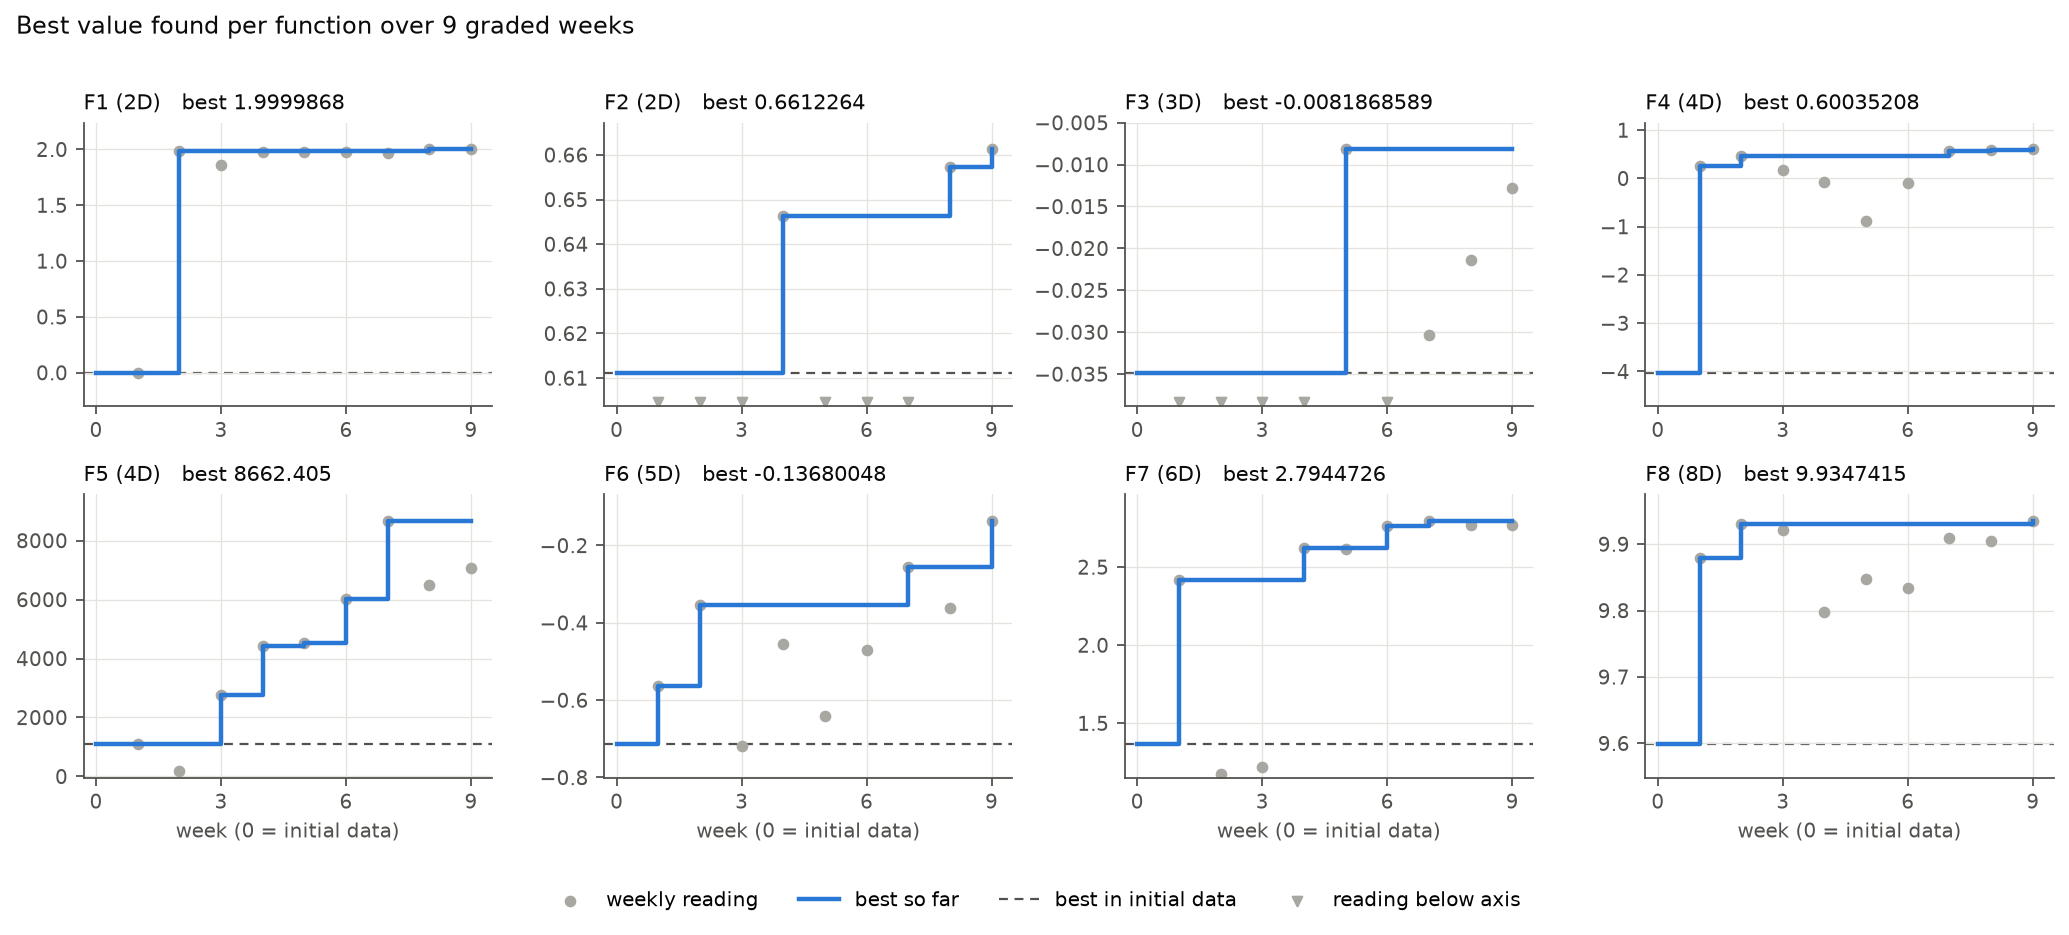

In [3]:
spec = importlib.util.spec_from_file_location("make_figures", ROOT / "scripts" / "make_figures.py")
mf = importlib.util.module_from_spec(spec); spec.loader.exec_module(mf)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
mf.best_so_far(DATA, FIG)
display(Image(FIG / "best_so_far.png"))

## 3. Calibration record

Every query was submitted with a written prediction and a stated range, and
the following week's result graded it.

This is the only test of the surrogate at points it hasn't seen. That
matters because every query is exactly such a point.

overall: 58/71 = 82% of predictions inside their stated range


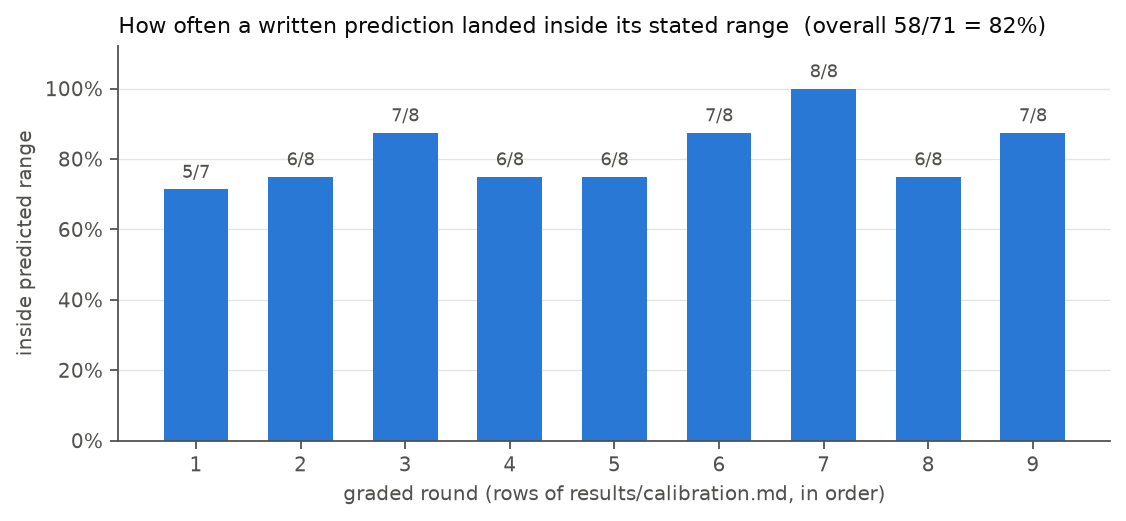

,round,hits,of,notes
0,1 -> 2,5,7,"F4, F7 beat their bands (upside); F1 quadratic..."
1,2 -> 3,6,8,F7 miss below -> peak sharper than modelled; F...
2,3 -> 4,7,8,"F4 hard miss -> trust region adopted (ls cap, ..."
3,4 -> 5,6,8,F2 miss at the incumbent's doorstep -> noise s...
4,5 -> 6,6,8,"F3 sd overconfident; F6 x5-up hurt -> tighter,..."
5,6 -> 7,7,8,F5 ABOVE band (+33% record) -> edge sweep acce...
6,7 -> 8,8,8,perfect calibration week; 4 new bests
7,8 -> 9,6,8,"F3/F6 marginal; F1 fit predicted 2.0009, obser..."
8,9 -> 10,7,8,F6 broke its band UPWARD (-0.137); F8 plateau ...


In [4]:
txt = (ROOT / "results" / "calibration.md").read_text()
cal = pd.DataFrame(re.findall(r"^\|\s*(\d+\s*->\s*\d+)\s*\|\s*(\d+)/(\d+)[^|]*\|\s*(.*?)\s*\|$", txt, flags=re.M),
                   columns=["round", "hits", "of", "notes"]).astype({"hits": int, "of": int})
print(f"overall: {cal.hits.sum()}/{cal.of.sum()} = {cal.hits.sum()/cal.of.sum():.0%} of predictions inside their stated range")
mf.calibration_hits(ROOT / "results", FIG)
display(Image(FIG / "calibration_hits.png"))
cal

## 4. The regimes, worked through

### 4a. Whole-domain EI vs a trust region: F3

Expected Improvement over the whole domain is drawn to regions the model
hasn't explored, because its uncertainty is high there. The trust-region
box, with half-width 0.03, keeps the proposal next to the spike at
(0.484, 0.760, 0.488).

In [5]:
cfg = CONFIG[3]
X, y = data.load(DATA, 3)
gp = surrogates.fit_gp(X, y, ls_hi=cfg.get("ls_hi", 10.0))
inc = X[np.argmax(y)]
for name, kw in [("whole-domain EI (xi=0.01)", dict(xi=0.01)),
                 ("trust region (config)", dict(xi=cfg["xi"], lo=inc - cfg["box_half"], hi=inc + cfg["box_half"]))]:
    q, _ = acquisition.propose(gp, 3, y.max(), **kw)
    mu, sd = gp.predict(q.reshape(1, -1), return_std=True)
    print(f"{name:27s} {data.portal_format(q)}  mu={mu[0]:+.4f} sd={sd[0]:.4f}  distance from incumbent={np.linalg.norm(q - inc):.3f}")
print("fitted lengthscales:", np.round(gp.kernel_.k2.length_scale, 3))

whole-domain EI (xi=0.01)   0.513292-0.000001-0.517276  mu=-0.0174 sd=0.0602  distance from incumbent=0.761
trust region (config)       0.513975-0.730029-0.518443  mu=-0.0102 sd=0.0122  distance from incumbent=0.052
fitted lengthscales: [0.445 1.116 0.178]


### 4b. Trust region with capped lengthscales: F7

F7 has a sharp ridge on the x1 = 0 face. Capping the lengthscales at 2.0
stops ARD from writing any input off as irrelevant, and the 0.04 box keeps
each step small.

incumbent: 0.000001-0.173591-0.443617-0.288725-0.314743-0.691965 y=2.794473
proposal:  0.000001-0.165422-0.483617-0.274693-0.302543-0.712795 mu=2.7813 +/- 0.0412
step per input: [ 0.     -0.0082  0.04   -0.014  -0.0122  0.0208]


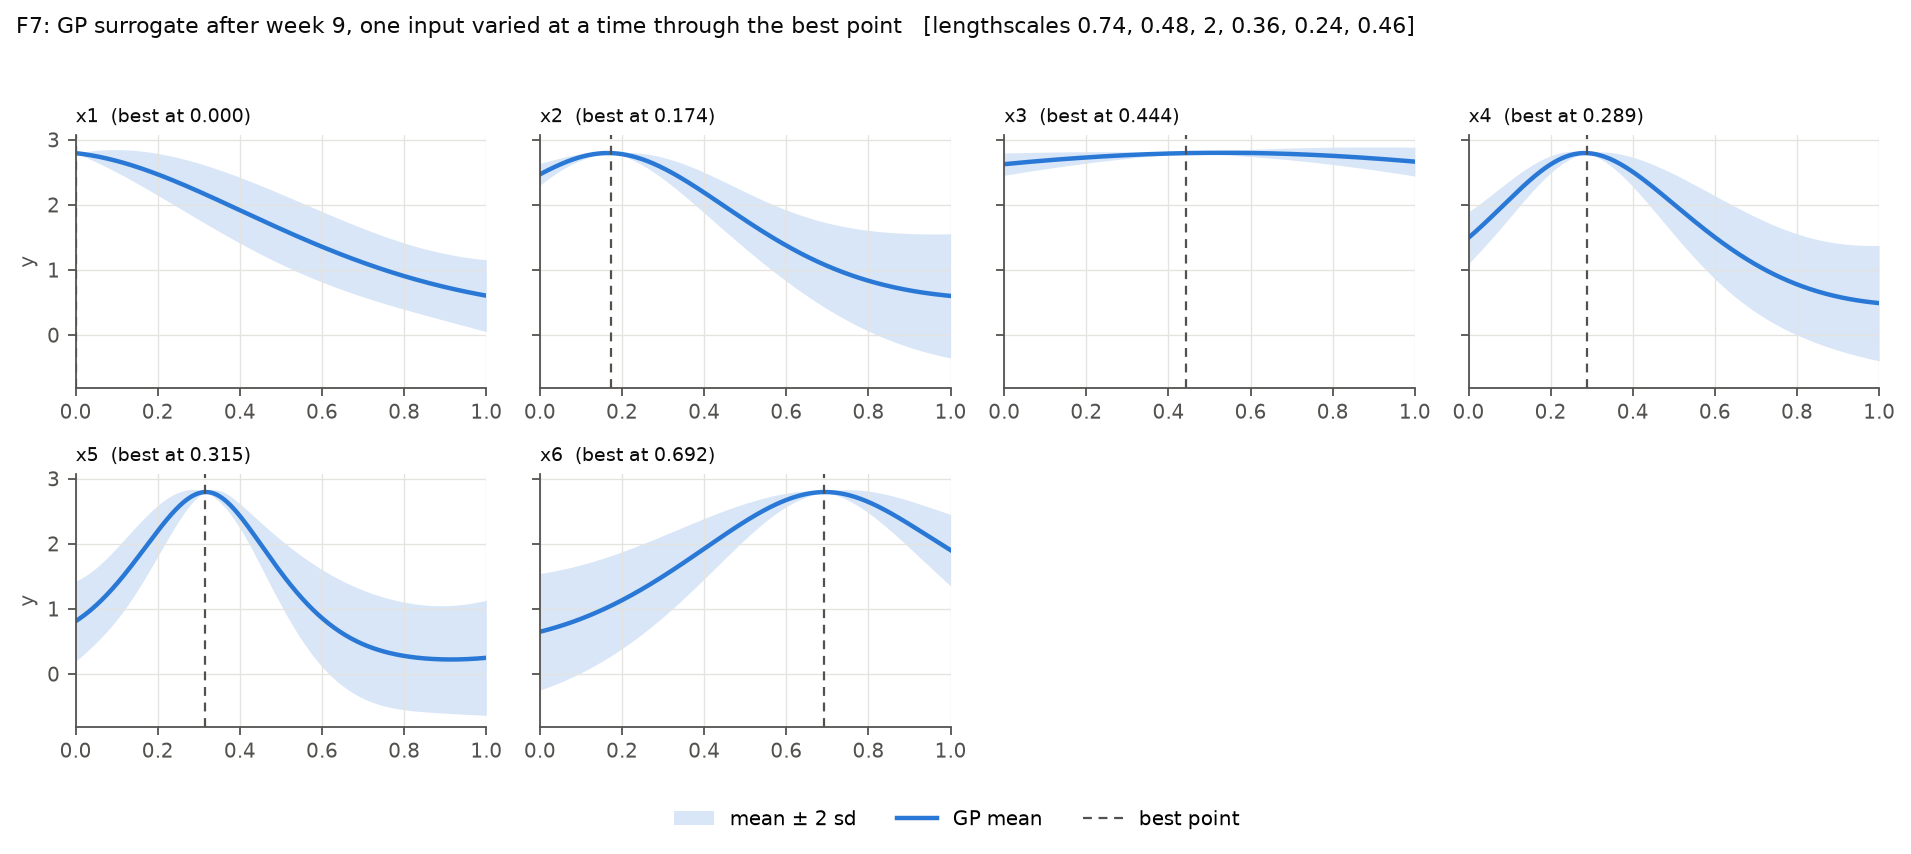

In [6]:
cfg = CONFIG[7]
X, y = data.load(DATA, 7)
gp = surrogates.fit_gp(X, y, ls_hi=cfg["ls_hi"])
inc = X[np.argmax(y)]
q, _ = acquisition.propose(gp, 6, y.max(), xi=cfg["xi"], lo=inc - cfg["box_half"], hi=inc + cfg["box_half"])
mu, sd = gp.predict(q.reshape(1, -1), return_std=True)
print("incumbent:", data.portal_format(inc), f"y={y.max():.6f}")
print("proposal: ", data.portal_format(q), f"mu={mu[0]:.4f} +/- {sd[0]:.4f}")
print("step per input:", np.round(q - inc, 4))
display(Image(FIG / "surrogate_F7.png"))

### 4c. Parametric triangulation: F4

The model is an isotropic quadratic, `a + b·x + c·|x|²`, fitted to the raw
readings within 0.13 of the incumbent. The fit's vertex is the next query.

In [7]:
X, y = data.load(DATA, 4)
inc = X[np.argmax(y)]
c, peak, r2, ok = triangulation.triangulate(X, y, radius=CONFIG[4]["radius"], anchor=inc, use_log_magnitude=False)
print(f"fit ok={ok}  R2={r2:.4f}  fitted peak={peak:.4f}  points used={(np.linalg.norm(X - inc, axis=1) < 0.13).sum()}")
print("vertex        :", data.portal_format(c))
print("submitted wk10:", log.loc[(log.week == 10) & (log.function == "F4"), "query"].item())
print("F4 weeks 7-9  :", np.round(y[-3:], 5))

fit ok=True  R2=0.9933  fitted peak=0.6145  points used=9
vertex        : 0.408815-0.400815-0.365021-0.411389
submitted wk10: 0.408815-0.400815-0.365021-0.411389
F4 weeks 7-9  : [0.5721  0.59781 0.60035]


### 4d. Value fit near the peak: F1

F1 was first located by triangulating on log-magnitudes, in weeks 1–2. It
is now refined with the same isotropic form, fitted to the raw readings
above half the current best.

readings used: 8  R2=0.999996  fitted peak=2.000001
vertex        : 0.628534-0.628591
submitted wk10: 0.628534-0.628591


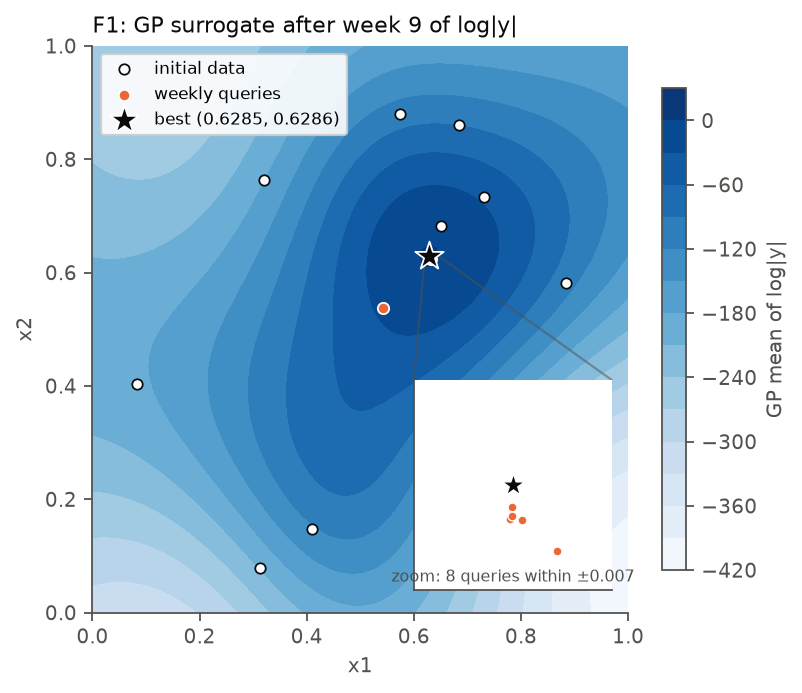

In [8]:
X, y = data.load(DATA, 1)
m = y > 0.5 * y.max()
c, peak, r2, ok = triangulation.isotropic_fit(X[m], y[m])
print(f"readings used: {m.sum()}  R2={r2:.6f}  fitted peak={peak:.6f}")
print("vertex        :", data.portal_format(c))
print("submitted wk10:", log.loc[(log.week == 10) & (log.function == "F1"), "query"].item())
display(Image(FIG / "surrogate_F1.png"))

### 4e. Posterior-mean argmax on a noisy function: F2

F2 carries a WhiteKernel. The fitted noise level comes out of the marginal
likelihood, and the next query is the argmax of the posterior mean inside
the configured box, rather than the argmax of EI.

In [9]:
cfg = CONFIG[2]
X, y = data.load(DATA, 2)
gp = surrogates.fit_gp(X, y, noisy=True)
print("fitted kernel:", gp.kernel_)
noise_sd = np.sqrt(gp.kernel_.k2.noise_level) * gp._y_train_std
print(f"implied noise sd on the y scale: {noise_sd:.3f}")
lo, hi = map(np.asarray, cfg["box"])
q, _ = acquisition.propose(gp, 2, y.max(), lo=lo, hi=hi, objective="mean")
mu, sd = gp.predict(q.reshape(1, -1), return_std=True)
print("posterior-mean argmax:", data.portal_format(q), f"mu={mu[0]:.4f} +/- {sd[0]:.4f}")
print("submitted wk10       :", log.loc[(log.week == 10) & (log.function == "F2"), "query"].item())

fitted kernel: 1.11**2 * Matern(length_scale=[0.0771, 10], nu=2.5) + WhiteKernel(noise_level=0.0584)
implied noise sd on the y scale: 0.060
posterior-mean argmax: 0.691909-0.999999 mu=0.5915 +/- 0.0636
submitted wk10       : 0.691909-0.999999


### 4f. Bank: F5

The log-GP followed the trend to the (1, 1, 1, 1) corner. Each probe that
stepped back from the corner lost value, so week 10 re-queries the corner.
Because it repeats a point exactly, the result also tests whether repeat
readings are identical.

In [10]:
f5 = log[log.function == "F5"][["week", "query", "observed"]]
f5

,week,query,observed
4,1,0.000001-0.581912-0.882310-0.999999,1095.3250783628
12,2,0.000001-0.014008-0.197475-0.999999,192.0910177942
20,3,0.000001-0.824963-0.999999-0.999999,2767.7701914297
28,4,0.000001-0.999999-0.999999-0.999999,4440.4808738393
36,5,0.400000-0.999999-0.999999-0.999999,4540.3377192312
44,6,0.800000-0.999999-0.999999-0.999999,6027.7244061398
52,7,0.999999-0.999999-0.999999-0.999999,8662.4050012483
60,8,0.999999-0.850000-0.999999-0.999999,6495.0315739000
68,9,0.999999-0.999999-0.900000-0.999999,7073.3929968159
76,10,0.999999-0.999999-0.999999-0.999999,NaN


## 5. Reproducibility: re-deriving the week-10 queries

Run on this 9-week data, the driver should regenerate the submitted week-10
queries.

In [11]:
outp = subprocess.run([sys.executable, str(ROOT / "scripts" / "weekly_run.py"), "--data", str(DATA)],
                      capture_output=True, text=True).stdout
derived = {l.split(":")[0]: l.split()[1] for l in outp.splitlines() if l.startswith("F")}
sub = log[log.week == 10].set_index("function")["query"]
chk = pd.DataFrame({"submitted": sub, "re-derived": pd.Series(derived)})
chk["max |diff|"] = [float(np.abs(np.array(a.split("-"), float) - np.array(b.split("-"), float)).max())
                     for a, b in zip(chk.submitted, chk["re-derived"])]
print(outp)
chk

F1: 0.628534-0.628591   (triangulated centre, predicted peak ~ 2, R2 = 1.000)
F2: 0.691909-0.999999   (mu = 0.5915 +/- 0.0636, regime = mean_argmax)
F3: 0.513975-0.730029-0.518443   (mu = -0.01021 +/- 0.0122, regime = trust_region)
F4: 0.408815-0.400815-0.365021-0.411389   (triangulated centre, predicted peak ~ 0.6145, R2 = 0.993)
F5: 0.999999-0.999999-0.999999-0.999999   (bank best-known point)
F6: 0.427581-0.382223-0.730707-0.724506-0.110571   (mu = -0.08877 +/- 0.06139, regime = trust_region)
F7: 0.000001-0.165422-0.483617-0.274693-0.302543-0.712795   (mu = 2.781 +/- 0.0412, regime = trust_region)
F8: 0.092958-0.150582-0.136049-0.000001-0.999999-0.471948-0.203583-0.999999   (mu = 9.946 +/- 0.01003, regime = trust_region)



,submitted,re-derived,max |diff|
F1,0.628534-0.628591,0.628534-0.628591,0.000000
F2,0.691909-0.999999,0.691909-0.999999,0.000000
F3,0.513975-0.730029-0.518443,0.513975-0.730029-0.518443,0.000000
F4,0.408815-0.400815-0.365021-0.411389,0.408815-0.400815-0.365021-0.411389,0.000000
F5,0.999999-0.999999-0.999999-0.999999,0.999999-0.999999-0.999999-0.999999,0.000000
F6,0.427581-0.382223-0.730707-0.724506-0.110571,0.427581-0.382223-0.730707-0.724506-0.110571,0.000000
F7,0.000001-0.165421-0.483617-0.274693-0.302544-0...,0.000001-0.165422-0.483617-0.274693-0.302543-0...,0.000001
F8,0.092957-0.150582-0.136047-0.000001-0.999999-0...,0.092958-0.150582-0.136049-0.000001-0.999999-0...,0.000002
